# TP 16 — Segmentation du catalogue : correction commentée

**Mode cours.** Ce notebook refait la matinée du TP 16 (sections 1 à 4) en s'appuyant sur votre `clustering.ipynb`. À chaque étape :

- ❌ **Votre version** : ce que fait votre notebook, rejoué à l'identique, avec son résultat ;
- ✅ **Correction** : ce que je propose à la place ;
- 🎓 **Pourquoi** : en quoi votre version est fausse ou fragile, et pourquoi la correction est meilleure.

> Les tableaux sont recalculés à l'exécution. Les chiffres cités dans les commentaires proviennent des sorties de ce notebook, ou de votre notebook quand c'est signalé.

**Plan** : 0. Périmètre · 1. Valeurs impossibles · 2. Imputation · 3. Asymétrie et normalisation · 4. Mesurer correctement · 5. Choisir k · 6. Interpréter et nommer · 7. Bilan

*Source des données : Open Food Facts (licence ODbL).*

In [41]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (calinski_harabasz_score, davies_bouldin_score,
                             silhouette_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
pd.set_option("display.precision", 2)
pd.set_option("display.width", 200)
plt.style.use("seaborn-v0_8-darkgrid")

df = pd.read_parquet("../data-nutriscope/nutriscope_ml_sample.parquet")

# Les 7 nutriments du TP 16 (fibres, pas glucides)
COLS = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "sugars_100g",
        "salt_100g", "fiber_100g", "proteins_100g"]
# Les 7 nutriments de VOTRE notebook (KEY_NUTRIENTS : glucides, pas fibres)
VOS_COLS = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g",
            "carbohydrates_100g", "sugars_100g", "proteins_100g", "salt_100g"]
print(f"{len(df)} produits, {df['pnns_groups_1'].nunique()} rayons, "
      f"{df['pnns_groups_2'].nunique()} sous-catégories")

30041 produits, 10 rayons, 39 sous-catégories


## 0. Le périmètre

### ❌ Votre version
Votre notebook ne garde que le rayon `Beverages` : `df_grouped.get_group("Beverages")`.

In [42]:
rayons = df["pnns_groups_1"].value_counts().to_frame("produits")
rayons["part %"] = (100 * rayons["produits"] / len(df)).round(1)
display(rayons)

,produits,part %
pnns_groups_1,,
Sugary snacks,6487,21.6
Fish Meat Eggs,5494,18.3
Milk and dairy products,3768,12.5
Cereals and potatoes,3264,10.9
Composite foods,2576,8.6
Beverages,2233,7.4
Fat and sauces,2192,7.3
Fruits and vegetables,2063,6.9
Salty snacks,1921,6.4


### 🎓 Pourquoi c'est un problème
Le TP demande de **segmenter le catalogue** de l'équipe : « *regrouper les produits qui se ressemblent sur le plan nutritionnel, pour comprendre ce que contient réellement notre base* ». Les boissons ne représentent que ~7 % du fichier.

Le périmètre n'est **pas** la cause de votre « 1 gros groupe + de petites poches » (2116 produits sur 2233 dans le même cluster) : on verra que c'est surtout l'absence de `log1p` (section 3), les erreurs de saisie (section 1) n'expliquant que la poche de 5 produits. Mais il amplifie le problème : dans un seul rayon, les produits sont très semblables (les boissons sont presque toutes pauvres en gras, en sel et en protéines), et quelques valeurs atypiques suffisent à dominer les distances.

### ✅ Correction
On segmente **tout le catalogue**. Les boissons seront un des « quartiers » de la carte, et on pourra vérifier plus loin qu'elles se retrouvent bien ensemble.

> Si votre équipe a décidé au TP 2 de ne couvrir que les boissons, c'est possible, mais il faut alors le justifier dans le notebook. Ce n'est pas ce que demande le TP.

## 1. Les valeurs impossibles (exercice 1 du TP)

### ❌ Votre version
Votre notebook n'a **aucun contrôle de plausibilité**. Regardons ce que cela laisse passer dans les boissons.

In [43]:
bev = df[df["pnns_groups_1"] == "Beverages"]
suspects = bev[bev["salt_100g"] >= 10][["product_name", "pnns_groups_2", "salt_100g", "energy-kcal_100g"]]
print("Boissons à 10 g de sel ou plus pour 100 g (l'eau de mer en contient ~3,5 g) :")
display(suspects)

Boissons à 10 g de sel ou plus pour 100 g (l'eau de mer en contient ~3,5 g) :


,product_name,pnns_groups_2,salt_100g,energy-kcal_100g
243,Grape Flavored Juice Drink from Concentrate,Sweetened beverages,21.19,47.46
2025,Organic Cashewmilk,Plant-based milk substitutes,27.34,43.75
5569,"Nectar Orange Pêche Et Abricot, 2 Litres, Marq...",Fruit juices,12.00,46.00
28703,Jugo de mango,Fruit juices,12.00,48.00
30008,Minuman Laici (Lychee drink),Sweetened beverages,10.00,20.00


Votre cluster 2 (« Boissons salées / atypiques, micro-groupe ») était exactement ces produits. **Aucun n'est salé** : un jus de raisin, un lait de cajou et un nectar ne contiennent pas 12 à 27 g de sel pour 100 g. Ce sont des erreurs de saisie (unité, colonne décalée). Sans contrôle préalable, ce groupe a été lu comme une famille de produits alors qu'il ne rassemble que des erreurs de données : c'est précisément le piège que l'exercice 1 du TP veut éviter.

### ✅ Correction
La règle du TP (lipides + sucres + protéines + fibres > 100 g, ou kcal > 900) ne suffit pas : **le sel n'y figure pas**, elle ne verrait pas ces produits. Un seuil global sur le sel serait dangereux, car certains produits (nuoc-mâm, câpres au sel, bouillons) sont **vraiment** très salés. On ajoute donc une **règle métier par rayon** : une boisson n'est pas plus salée que l'eau de mer (environ 3,5 g de sels dissous, dont ~2,7 g de chlorure de sodium : seuil volontairement large). On ajoute aussi une **tolérance d'arrondi de 1 g** à la règle de somme : sans elle, une huile étiquetée « 100 g de lipides + 0,5 g de protéines + 0,5 g de sucres » serait écartée à tort. Et surtout on **compte** chaque règle, puis on **regarde** ce qu'elle écarte.

In [44]:
reglesTP = {
    "TP : lipides+sucres+prot.+fibres > 101 g (arrondis tolérés)": df[["fat_100g", "sugars_100g", "proteins_100g", "fiber_100g"]].fillna(0).sum(axis=1) > 101,
    "TP : kcal > 900": df["energy-kcal_100g"] > 900,
}
reglesEquipe = {
    "Somme avec le sel > 101 g": df[["fat_100g", "sugars_100g", "proteins_100g", "fiber_100g", "salt_100g"]].fillna(0).sum(axis=1) > 101,
    "Boisson à plus de 3,5 g de sel (eau de mer)": (df["pnns_groups_1"] == "Beverages") & (df["salt_100g"] > 3.5),
    "Saturés > lipides + 0,5": df["saturated-fat_100g"] > df["fat_100g"] + 0.5,
    "Sucres > glucides + 0,5": df["sugars_100g"] > df["carbohydrates_100g"] + 0.5,
}
tableau = pd.DataFrame({"produits touchés": {n: int(m.sum()) for n, m in {**reglesTP, **reglesEquipe}.items()}})
display(tableau)

masque_impossible = np.logical_or.reduce(list({**reglesTP, **reglesEquipe}.values()))
print(f"\nProduits aberrants écartés (toutes règles) : {int(masque_impossible.sum())} sur {len(df)}")
print("Règle du TP seule :", int(np.logical_or.reduce(list(reglesTP.values())).sum()))

cat = df.loc[~masque_impossible].reset_index(drop=True)
print(f"✓ Catalogue conservé : {len(cat)} produits")
reste = cat[(cat["pnns_groups_1"] == "Beverages") & (cat["salt_100g"] >= 10)]
print(f"Boissons à 10 g de sel ou plus restant dans le catalogue : {len(reste)}  (attendu : 0)")

# Une règle se vérifie : on regarde ce qu'elle écarte
for nom, m in {**reglesTP, **reglesEquipe}.items():
    if m.sum():
        print(f"\n--- {nom} : {int(m.sum())} produits, exemples :")
        display(df.loc[m, ["product_name", "pnns_groups_1", "fat_100g", "sugars_100g", "proteins_100g", "salt_100g"]].head(6))

,produits touchés
TP : lipides+sucres+prot.+fibres > 101 g (arrondis tolérés),26
TP : kcal > 900,0
Somme avec le sel > 101 g,36
"Boisson à plus de 3,5 g de sel (eau de mer)",10
"Saturés > lipides + 0,5",0
"Sucres > glucides + 0,5",0



Produits aberrants écartés (toutes règles) : 46 sur 30041
Règle du TP seule : 26
✓ Catalogue conservé : 29995 produits
Boissons à 10 g de sel ou plus restant dans le catalogue : 0  (attendu : 0)

--- TP : lipides+sucres+prot.+fibres > 101 g (arrondis tolérés) : 26 produits, exemples :


,product_name,pnns_groups_1,fat_100g,sugars_100g,proteins_100g,salt_100g
397,Extra Creamy Peanut Butter,Fat and sauces,46.67,13.33,26.67,7.22
2774,Milk Chocolate Eggs With Coconut,Sugary snacks,35.60,53.00,4.50,0.30
4557,Noix de cajou truffe,Salty snacks,47.00,5.40,25.00,1.20
6481,Bonbons Tagada Pink & Pik,Sugary snacks,0.50,73.00,2.80,0.24
8177,Huile d’avocat,Fat and sauces,83.00,0.00,0.00,0.00
8451,Huile de friture NETTO 6X2L,Fat and sauces,100.00,0.50,0.50,0.01



--- Somme avec le sel > 101 g : 36 produits, exemples :


,product_name,pnns_groups_1,fat_100g,sugars_100g,proteins_100g,salt_100g
397,Extra Creamy Peanut Butter,Fat and sauces,46.67,13.33,26.67,7.22
2774,Milk Chocolate Eggs With Coconut,Sugary snacks,35.60,53.00,4.50,0.30
4557,Noix de cajou truffe,Salty snacks,47.00,5.40,25.00,1.20
5263,1/6 jambon sec s/os,Fish Meat Eggs,13.90,0.10,85.00,5.25
6481,Bonbons Tagada Pink & Pik,Sugary snacks,0.50,73.00,2.80,0.24
8177,Huile d’avocat,Fat and sauces,83.00,0.00,0.00,0.00



--- Boisson à plus de 3,5 g de sel (eau de mer) : 10 produits, exemples :


,product_name,pnns_groups_1,fat_100g,sugars_100g,proteins_100g,salt_100g
243,Grape Flavored Juice Drink from Concentrate,Beverages,0.00,10.85,0.00,21.19
2025,Organic Cashewmilk,Beverages,2.62,0.88,1.31,27.34
5569,"Nectar Orange Pêche Et Abricot, 2 Litres, Marq...",Beverages,0.00,10.70,0.00,12.00
24480,Tradizione italiano,Beverages,50.00,8.00,9.00,8.00
25345,Ice Pulpe Orange 1.5cl,Beverages,0.00,4.00,0.03,5.49
25360,Mirinda POMME 1.5l,Beverages,0.00,13.00,0.00,4.00


🎓 **Limite connue** : la règle « boisson » ne s'applique qu'au rayon `Beverages`. Une « Teriyakisauce » est rangée par erreur dans `Alcoholic beverages` : son sel est réel, c'est son **rayon** qui est faux. Ce genre de cas se signale dans le journal, il ne se corrige pas par une règle sur les nutriments.

In [45]:
print("Produits « Alcoholic beverages » à plus de 3,5 g de sel (non écartés, à signaler) :")
display(cat.loc[(cat["pnns_groups_1"] == "Alcoholic beverages") & (cat["salt_100g"] > 3.5), ["product_name", "salt_100g"]])

Produits « Alcoholic beverages » à plus de 3,5 g de sel (non écartés, à signaler) :


,product_name,salt_100g
29313,Teriyakisauce,10.2


### 🎓 Pourquoi c'est mieux
- **Une règle = un compteur.** On sait ce qu'on écarte et pourquoi : ces chiffres vont dans `docs/journal.md`. Écarter « tout ce qui est loin de la médiane » serait faux, car un sirop à 80 g de sucres est **vrai**, alors qu'un jus à 16 g de sel est **faux**.
- **Écarter plutôt que corriger.** Nous ne savons pas d'où vient l'erreur (milligrammes ? sodium ?). Inventer une valeur serait pire.
- Le but n'est pas la perfection mais d'éviter que K-Means **consacre un groupe entier** à 5 erreurs.

## 2. Les valeurs manquantes (exercice 2 du TP)

### Votre version — et une correction de ma part
`SimpleImputer(strategy="median")` est ajusté sur `Z`, c'est-à-dire sur les **boissons seulement**. Ce n'est donc **pas** une médiane globale du catalogue : c'est la médiane du groupe sur lequel vous travaillez. **Votre principe est le bon.**

Reste deux points factuels, à vérifier ci-dessous :
1. sur vos 7 variables (`KEY_NUTRIENTS`), il n'y a **aucune valeur manquante** dans les boissons : l'imputeur ne fait rien ;
2. la colonne qui manque vraiment, ce sont les **fibres**, que vos variables n'incluent pas.

In [46]:
bev_cat = cat[cat["pnns_groups_1"] == "Beverages"]
print("Manquants dans VOS 7 variables, boissons :", int(bev_cat[VOS_COLS].isna().sum().sum()), "(votre imputation ne change donc rien)")
print(f"Manquants en fibres, boissons             : {100 * bev_cat['fiber_100g'].isna().mean():.0f} %\n")

manq = cat[COLS].isna().mean().mul(100).round(1).to_frame("% manquants")
display(manq[manq["% manquants"] > 0])

print("Médiane des fibres des boissons : rayon entier vs par sous-catégorie")
sc = bev_cat.groupby("pnns_groups_2")["fiber_100g"].median().round(2).to_frame("médiane fibres (sous-catégorie)")
sc.loc["--- médiane du rayon Beverages ---"] = round(bev_cat["fiber_100g"].median(), 2)
display(sc)
print("Médiane des fibres par rayon, sur tout le catalogue :")

rayon_fib = cat.groupby("pnns_groups_1")["fiber_100g"].median().round(1).to_frame("médiane fibres")
rayon_fib.loc["--- TOUT LE CATALOGUE ---"] = cat["fiber_100g"].median()
display(rayon_fib.sort_values("médiane fibres"))

Manquants dans VOS 7 variables, boissons : 0 (votre imputation ne change donc rien)
Manquants en fibres, boissons             : 39 %



,% manquants
fiber_100g,46.8


Médiane des fibres des boissons : rayon entier vs par sous-catégorie


,médiane fibres (sous-catégorie)
pnns_groups_2,
Artificially sweetened beverages,0.00
Fruit juices,0.40
Fruit nectars,0.50
Plant-based milk substitutes,0.50
Sweetened beverages,0.00
Teas and herbal teas and coffees,0.00
Unsweetened beverages,0.23
Waters and flavored waters,0.00
--- médiane du rayon Beverages ---,0.10


Médiane des fibres par rayon, sur tout le catalogue :


,médiane fibres
pnns_groups_1,
Alcoholic beverages,0.00
Fish Meat Eggs,0.00
Milk and dairy products,0.00
Beverages,0.10
Fat and sauces,0.50
--- TOUT LE CATALOGUE ---,1.32
Composite foods,1.60
Sugary snacks,2.10
Fruits and vegetables,2.20


### 🎓 Ce qui était juste, ce qui change
- **Votre principe est le bon** : imputer par la médiane *du groupe* plutôt que du catalogue entier. Tant que vous restez sur les boissons, vous le faisiez sans le savoir.
- **Ce qui change avec le TP** n'est pas une erreur de votre part mais une conséquence du changement de périmètre : en segmentant **tout le catalogue**, un `SimpleImputer` placé directement dans le pipeline aurait calculé *une* médiane pour tous les rayons (voir le dernier tableau : de 0 à 4 g de fibres selon le rayon). Il faut donc imputer **par groupe**, ce que `SimpleImputer` ne fait pas tout seul.
- **Pourquoi la sous-catégorie plutôt que le rayon** (consigne du TP) : c'est un niveau plus fin. Pour les boissons l'écart est modeste (de 0 à 0,5 g, voir le tableau), donc **ne le présentez pas comme un gros gain**. Il compte surtout pour les rayons hétérogènes (« Composite foods », « Cereals and potatoes »).

### ✅ Correction
Médiane de la **sous-catégorie** (`pnns_groups_2`), puis médiane globale en dernier recours, avec les fibres incluses. On garde une trace des lignes imputées, car la substitution de l'après-midi n'utilisera jamais ces valeurs.

In [47]:
features = cat[COLS].copy()
cat["imputee"] = cat[COLS].isna().any(axis=1)
for col in COLS:
    features[col] = features[col].fillna(cat.groupby("pnns_groups_2")[col].transform("median"))
    features[col] = features[col].fillna(cat[col].median())

print(f"Produits avec au moins un nutriment imputé : {int(cat['imputee'].sum())}")
print(f"Manquants restants dans features           : {int(features.isna().sum().sum())}  (attendu : 0)")

Produits avec au moins un nutriment imputé : 14051
Manquants restants dans features           : 0  (attendu : 0)


🎓 **Ce que cela apporte** : on suppose qu'un produit aux fibres inconnues ressemble aux produits **de son usage** (une boisson à une boisson). C'est une hypothèse, pas une certitude, et un affinement de votre approche plutôt qu'une correction. Le Nutri-Score, lui, ne s'impute jamais.

## 3. Asymétrie et normalisation (exercice 3 du TP)

### ❌ Votre version
`StandardScaler` seul, sans transformation. Mesurons l'asymétrie, puis ce que devient une valeur extrême après normalisation.

In [48]:
asymetrie = features.skew().sort_values(ascending=False)
display(asymetrie.round(2).to_frame("asymétrie (skewness)"))

X_std = StandardScaler().fit_transform(features)
z_max = pd.Series(np.abs(X_std).max(axis=0), index=COLS).round(1)
print("Valeur absolue maximale après StandardScaler seul (en écarts-types) :")
print(z_max.sort_values(ascending=False).to_string())

,asymétrie (skewness)
salt_100g,8.02
fiber_100g,5.21
saturated-fat_100g,3.10
fat_100g,2.07
sugars_100g,1.92
proteins_100g,1.12
energy-kcal_100g,0.68


Valeur absolue maximale après StandardScaler seul (en écarts-types) :
salt_100g             33.9
fiber_100g            26.4
saturated-fat_100g    11.1
proteins_100g          7.7
sugars_100g            4.6
fat_100g               4.5
energy-kcal_100g       3.3


🎓 **Pourquoi c'est un problème.** Les teneurs en sel, en fibres ou en graisses saturées ont une queue très longue à droite : quelques produits très riches, une masse proche de zéro. Après `StandardScaler`, ces rares produits sont à **plus de 10 écarts-types** de la moyenne (voir ci-dessus, jusqu'à ~26 pour les fibres). Dans un calcul de distance, ils pèsent plus que des milliers de produits ordinaires, et K-Means leur réserve des clusters à eux. (Ces chiffres portent sur le catalogue et ses 7 variables ; vérifions ci-dessous l'effet sur **vos** boissons et **vos** variables.)

### ✅ Correction : `log1p` sur les colonnes d'asymétrie > 1, puis `StandardScaler`

In [49]:
COLS_LOG = list(asymetrie[asymetrie > 1].index)
features_t = features.copy()
features_t[COLS_LOG] = np.log1p(features_t[COLS_LOG])

scaler = StandardScaler()          # à conserver : l'API devra appliquer la même transformation
X = scaler.fit_transform(features_t)

print("Colonnes transformées par log1p :", COLS_LOG)
print("Moyennes de X (attendu ~0)    :", X.mean(axis=0).round(2))
print("Écarts-types de X (attendu 1) :", X.std(axis=0).round(2))
print("\nAsymétrie après log1p :")
print(pd.Series(features_t.skew(), index=COLS).round(2).to_string())
print("\nValeur absolue maximale après log1p + StandardScaler :")
print(pd.Series(np.abs(X).max(axis=0), index=COLS).round(1).to_string())

Colonnes transformées par log1p : ['salt_100g', 'fiber_100g', 'saturated-fat_100g', 'fat_100g', 'sugars_100g', 'proteins_100g']
Moyennes de X (attendu ~0)    : [ 0.  0. -0. -0.  0.  0. -0.]
Écarts-types de X (attendu 1) : [1. 1. 1. 1. 1. 1. 1.]

Asymétrie après log1p :
energy-kcal_100g      0.68
fat_100g             -0.18
saturated-fat_100g    0.34
sugars_100g           0.46
salt_100g             1.21
fiber_100g            0.68
proteins_100g        -0.39

Valeur absolue maximale après log1p + StandardScaler :
energy-kcal_100g      3.3
fat_100g              1.9
saturated-fat_100g    3.0
sugars_100g           2.2
salt_100g             7.1
fiber_100g            5.0
proteins_100g         2.4


**Preuve sur votre périmètre.** Qu'est-ce qui produisait votre « 1 bloc + des poches » : les erreurs de saisie, ou l'absence de `log1p` ? On isole chaque effet, sur vos boissons et vos 7 variables, à k = 5 comme vous.

In [50]:
bev_clean = cat.loc[cat["pnns_groups_1"] == "Beverages", VOS_COLS]
cas = {
    "Votre version (brut, StandardScaler)": StandardScaler().fit_transform(df.loc[df["pnns_groups_1"] == "Beverages", VOS_COLS]),
    "Nettoyé, StandardScaler": StandardScaler().fit_transform(bev_clean),
    "Nettoyé + log1p, StandardScaler": StandardScaler().fit_transform(np.log1p(bev_clean)),
}
lignes = []
for nom, Zc in cas.items():
    t = np.sort(np.bincount(KMeans(n_clusters=5, n_init=10, random_state=SEED).fit_predict(Zc)))
    lignes.append({"préparation": nom, "produits": int(t.sum()), "tailles des 5 groupes": list(map(int, t)),
                   "plus gros groupe %": round(100 * t.max() / t.sum(), 0)})
display(pd.DataFrame(lignes).set_index("préparation"))

,produits,tailles des 5 groupes,plus gros groupe %
préparation,,,
"Votre version (brut, StandardScaler)",2233,"[5, 23, 41, 48, 2116]",95.0
"Nettoyé, StandardScaler",2222,"[22, 28, 40, 45, 2087]",94.0
"Nettoyé + log1p, StandardScaler",2222,"[41, 60, 174, 514, 1433]",64.0


🎓 **Lecture.** Le nettoyage ne fait disparaître que la poche de 5 erreurs : le bloc reste à ~94 %. C'est le **`log1p`** qui casse la domination du bloc. Vos autres poches (une vingtaine de poudres de café ou cacao, une quarantaine de sirops) sont de **vrais** produits extrêmes, pas des erreurs : sans `log1p`, ils écrasaient les distances.

🎓 **Pourquoi c'est mieux** : `log1p` comprime les grandes valeurs en gardant l'ordre des produits (un produit à 20 g de sel reste plus salé qu'un à 2 g), et accepte les zéros. Les écarts extrêmes tombent à quelques écarts-types : les groupes ne sont plus dictés par une poignée de cas. Le sel reste un peu asymétrique (~1,2 après `log1p`) : c'est acceptable, le critère du TP s'applique avant transformation et l'écart maximal n'est plus que de ~5 écarts-types.

> **Pour l'API (TP 23)** : `scaler`, `COLS_LOG` et les médianes d'imputation devront être **sauvegardés** (par exemple avec `joblib`), sinon un nouveau produit ne passera pas par la même transformation. Ce notebook les garde seulement en mémoire.

> Pourquoi pas `RobustScaler` comme dans le notebook du « labo » ? Parce que la médiane et l'IQR de la plupart des nutriments sont quasi nuls (médiane des lipides = 0 pour les boissons) : on divise par un nombre minuscule et un seul produit prend une valeur de plus de 900. Résultat : une silhouette de 0,97 trompeuse, 7 produits contre 2 226. On l'écarte.

## 4. Mesurer correctement la qualité

### ❌ Votre version — silhouette calculée sur les données brutes
Votre première version faisait :

```python
pipeline.fit(Z)                                  # clustering sur Z NORMALISÉ
silhouette_score(Z, km.labels_)                  # mais mesure sur Z BRUT
```
Rejouons-la, puis comparons avec la bonne mesure, sur vos boissons.

In [51]:
bev_raw = df.loc[df["pnns_groups_1"] == "Beverages", VOS_COLS]
vos_prepro = ColumnTransformer([("num", Pipeline([
    ("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), VOS_COLS)])

lignes = []
for k in range(2, 7):
    pipe = Pipeline([("prep", vos_prepro), ("km", KMeans(n_clusters=k, n_init=10, random_state=SEED))]).fit(bev_raw)
    lab = pipe.named_steps["km"].labels_
    Zs = pipe.named_steps["prep"].transform(bev_raw)
    lignes.append({"k": k,
                   "silhouette MESURÉE SUR LE BRUT (votre 1re version)": round(silhouette_score(bev_raw, lab), 3),
                   "silhouette dans l'espace du clustering (correcte)": round(silhouette_score(Zs, lab), 3),
                   "plus petit groupe": int(np.bincount(lab).min())})
display(pd.DataFrame(lignes).set_index("k"))

,silhouette MESURÉE SUR LE BRUT (votre 1re version),silhouette dans l'espace du clustering (correcte),plus petit groupe
k,,,
2,0.87,0.85,111
3,0.84,0.86,55
4,0.06,0.86,5
5,0.06,0.87,5
6,0.42,0.49,5


🎓 **Pourquoi c'est faux.** La silhouette compare, pour chaque point, la distance à son groupe et au groupe voisin. Il faut la calculer **dans l'espace où K-Means a travaillé** : les données normalisées. Sur le brut, les kcal (0 à 900) écrasent tout le reste. Votre phrase « chute catastrophique de la silhouette » venait de cet artefact.

Votre version corrigée (`Z_scaled`) est juste sur ce point. Mais sa colonne « plus petit groupe » dit l'essentiel : **5 produits dès k = 4.** Une silhouette de 0,87 avec un groupe de 5 individus ne signifie pas « bonne séparation », elle signifie « 5 points isolés loin du reste ».

### ❌ Votre version — le coude décalé
`KneeLocator(range(1, n+1), inertie)` alors que vos k commençaient à 2 : tout est décalé d'un cran. Démonstration avec une petite fonction du coude (distance maximale à la corde, sans bibliothèque) :

In [52]:
def coude(ks, inerties):
    # k du coude : point le plus éloigné de la droite entre le premier et le dernier point
    ks = np.asarray(list(ks), dtype=float)
    y = np.asarray(inerties, dtype=float)
    xn = (ks - ks.min()) / (ks.max() - ks.min())
    yn = (y - y.min()) / (y.max() - y.min())
    return int(ks[np.argmax(1 - xn - yn)])

# Exemple jouet : coude évident à k = 4
ks_exemple = range(2, 9)
inert_exemple = [1000, 600, 300, 250, 230, 220, 215]
print("Vrai coude de l'exemple              :", coude(ks_exemple, inert_exemple))
print("Avec un axe x décalé (range(1, n+1)) :", coude(range(1, len(inert_exemple) + 1), inert_exemple),
      "-> le k lu est faux d'une unité")

Vrai coude de l'exemple              : 4
Avec un axe x décalé (range(1, n+1)) : 3 -> le k lu est faux d'une unité


🎓 **Règle** : l'axe des x donné à n'importe quelle détection de coude doit être **exactement** la liste des k essayés. Votre notebook corrigé l'a fait (`k_range`) : ce point est réglé.

### ✅ Correction : le balayage de k, une seule fois, proprement
On mesure ce que demande le TP (coude + silhouette) **et** la taille du plus petit groupe, parce que c'est le critère « lisibilité métier » rendu chiffré.

,inertie,gain %,silhouette,davies_bouldin,calinski,plus petit groupe,plus grand groupe %
k,,,,,,,
2,147302,NaN,0.27,1.44,12759,13216,55.9
3,114047,22.6,0.29,1.26,12612,8489,37.2
4,98037,14.0,0.27,1.33,11413,7094,26.2
5,86835,11.4,0.30,1.20,10631,925,25.3
6,78482,9.6,0.29,1.24,10048,892,24.8
7,71474,8.9,0.28,1.24,9684,886,20.1
8,65845,7.9,0.29,1.25,9376,889,19.9
9,61390,6.8,0.28,1.27,9071,892,18.1
10,57273,6.7,0.29,1.23,8882,884,15.3


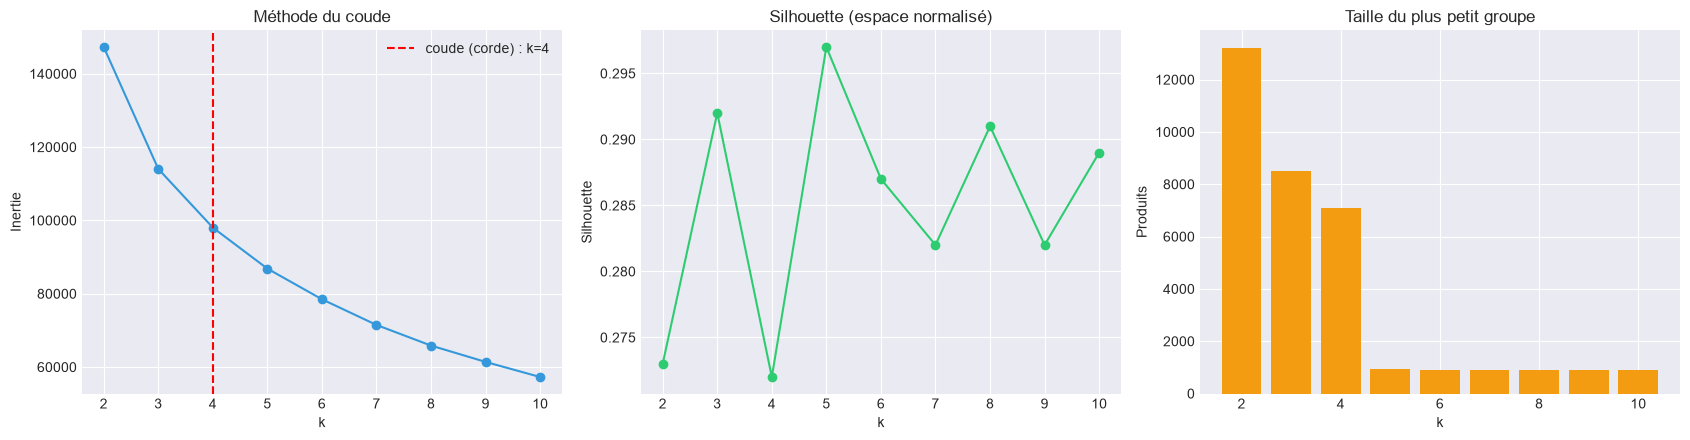

In [53]:
K_RANGE = range(2, 11)
modeles, lignes = {}, []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    modeles[k] = km
    lignes.append({
        "k": k,
        "inertie": int(km.inertia_),
        "silhouette": round(silhouette_score(X, km.labels_, sample_size=10000, random_state=SEED), 3),
        "davies_bouldin": round(davies_bouldin_score(X, km.labels_), 3),
        "calinski": int(calinski_harabasz_score(X, km.labels_)),
        "plus petit groupe": int(np.bincount(km.labels_).min()),
        "plus grand groupe %": round(100 * np.bincount(km.labels_).max() / len(X), 1),
    })
bal = pd.DataFrame(lignes).set_index("k")
bal.insert(1, "gain %", (100 * (bal["inertie"].shift(1) - bal["inertie"]) / bal["inertie"].shift(1)).round(1))
display(bal)

k_coude = coude(K_RANGE, bal["inertie"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(bal.index, bal["inertie"], "o-", color="#3498db"); ax[0].axvline(k_coude, color="red", ls="--", label=f"coude (corde) : k={k_coude}")
ax[0].set(title="Méthode du coude", xlabel="k", ylabel="Inertie"); ax[0].legend()
ax[1].plot(bal.index, bal["silhouette"], "o-", color="#2ecc71"); ax[1].set(title="Silhouette (espace normalisé)", xlabel="k", ylabel="Silhouette")
ax[2].bar(bal.index, bal["plus petit groupe"], color="#f39c12"); ax[2].set(title="Taille du plus petit groupe", xlabel="k", ylabel="Produits")
plt.tight_layout(); plt.show()

🎓 **Pourquoi c'est mieux, et ce que ça change.**

| | Votre notebook (boissons, sans `log1p`) | Cette correction (catalogue, `log1p`) |
|---|---|---|
| Plus petit groupe pour k = 5 | 5 produits | voir tableau : plusieurs centaines (≈ 900) |
| Plus grand groupe | 95 % des produits (k = 5) | voir tableau : de 56 % (k = 2) à 15 % (k = 10), 20 % à k = 7 |
| Silhouette | 0,85 – 0,87 (artefact de quelques outliers) | ~0,3 (honnête) |

Une silhouette autour de 0,3 vous semblera « mauvaise » à côté de 0,87. Elle ne l'est pas. Les nutriments d'aliments réels forment un continuum (un yaourt sucré ressemble un peu à une compote), pas des îlots séparés. Ici, votre 0,87 s'explique par la structure « 1 bloc de 2116 produits + quelques points isolés » : la silhouette est haute parce que ces rares points sont très loin du bloc, pas parce que le catalogue est bien découpé. Et regardez que la silhouette est **presque plate** de k = 2 à 10 : elle ne peut donc pas décider à notre place, c'est précisément ce que dit le cours (« aucune des deux courbes ne décide »).

## 5. Choisir k (exercice 5 du TP)

### ❌ Votre justification
Votre notebook disait :

> *« L'indice de Davies-Bouldin atteint son minimum optimal (`0,688`), garantissant une compacité maximale. La silhouette se maintient solidement à `0,694`. »*
> *« Une chute brutale de la silhouette (< 0,48) confirme qu'au-delà de 5 clusters, on tombe dans le sur-découpage artificiel. »*

Vérifions chaque affirmation contre **votre propre tableau**.

In [54]:
votre_tableau = pd.DataFrame({
    "k": range(2, 13),
    "silhouette": [0.8527, 0.8571, 0.8614, 0.8694, 0.4889, 0.4905, 0.4918, 0.4975, 0.5392, 0.5383, 0.5434],
    "davies_bouldin": [1.069, 0.882, 0.836, 0.688, 0.755, 0.795, 0.765, 0.710, 0.762, 0.815, 0.689],
    "plus petit groupe": [111, 55, 5, 5, 5, 5, 2, 2, 2, 2, 1],
}).set_index("k")      # valeurs relevées dans la sortie de votre notebook corrigé

verifs = pd.DataFrame([
    ["« silhouette à 0,694 » (k=5)", "0,694", f"{votre_tableau.loc[5, 'silhouette']}", "Inexact : sans doute une faute de frappe pour 0,8694"],
    ["« chute brutale (< 0,48) » (k≥6)", "< 0,48", f"{votre_tableau.loc[6:, 'silhouette'].min()} (min), {votre_tableau.loc[12, 'silhouette']} à k=12", "Chute réelle, chiffre inexact (0,489) ; remonte ensuite à 0,54"],
    ["« Davies-Bouldin minimum à k=5 »", "0,688", f"k=5 : 0,688 ; k=12 : {votre_tableau.loc[12, 'davies_bouldin']}", "Exact (minimum strict), mais lui aussi dicté par les poches de 5 produits"],
    ["k=5 « isole finement les profils »", "profils nets", f"plus petit groupe = {votre_tableau.loc[5, 'plus petit groupe']} produits", "Un groupe de 5 n'est pas un profil"],
], columns=["Affirmation", "Dite", "Votre tableau", "Verdict"])
display(verifs)

,Affirmation,Dite,Votre tableau,Verdict
0,"« silhouette à 0,694 » (k=5)","0,694",0.8694,Inexact : sans doute une faute de frappe pour ...
1,"« chute brutale (< 0,48) » (k≥6)","< 0,48","0.4889 (min), 0.5434 à k=12","Chute réelle, chiffre inexact (0,489) ; remont..."
2,« Davies-Bouldin minimum à k=5 »,"0,688","k=5 : 0,688 ; k=12 : 0.689","Exact (minimum strict), mais lui aussi dicté p..."
3,k=5 « isole finement les profils »,profils nets,plus petit groupe = 5 produits,Un groupe de 5 n'est pas un profil


🎓 **Pourquoi votre justification ne tient pas.** Elle commet l'erreur que le TP cite explicitement : *« justifier k uniquement par un score »*, et deux des chiffres sont mal recopiés. Le jury relira ce paragraphe : une phrase contredite par le tableau juste au-dessus affaiblit tout l'argument, même quand le reste est juste.

Le TP cite un second piège : *« choisir k = 2 parce que la silhouette est maximale »*. Votre première version y était exposée : la silhouette valait 0,87 à k = 2, avec un groupe de 2122 produits et un de 111. Vous l'avez évité en regardant la taille des groupes, ce qui était le bon réflexe.

### ✅ Correction : une règle de décision écrite *avant* de regarder
Trois critères, dans cet ordre, comme le demande le TP :
1. **Coude** : à partir de quel k le gain d'inertie devient-il faible ?
2. **Silhouette** : parmi les k raisonnables, aucun ne doit être nettement moins bon.
3. **Métier** : le plus petit groupe pèse au moins ~1 % du catalogue, et chaque groupe se décrit en une phrase.

In [55]:
SEUIL_PETIT = 0.01 * len(X)
bal["groupes ≥ 1 % ?"] = bal["plus petit groupe"] >= SEUIL_PETIT
display(bal[["gain %", "silhouette", "plus petit groupe", "groupes ≥ 1 % ?"]])
print(f"Seuil de taille : {SEUIL_PETIT:.0f} produits (1 % du catalogue de {len(X)})")
print(f"Coude (distance à la corde) : k = {k_coude}")

,gain %,silhouette,plus petit groupe,groupes ≥ 1 % ?
k,,,,
2,NaN,0.27,13216,True
3,22.6,0.29,8489,True
4,14.0,0.27,7094,True
5,11.4,0.30,925,True
6,9.6,0.29,892,True
7,8.9,0.28,886,True
8,7.9,0.29,889,True
9,6.8,0.28,892,True
10,6.7,0.29,884,True


Seuil de taille : 300 produits (1 % du catalogue de 29995)
Coude (distance à la corde) : k = 4


**Lecture.** Le gain d'inertie diminue progressivement : le coude est doux, pas net, ce qui est normal sur un continuum (la méthode de la corde désigne k = 4). La silhouette est plate. Le critère décisif devient donc le **métier**. Le seuil de 1 % ne départage rien ici (tous les k le passent). On formule donc **avant de regarder** un critère métier précis : *prendre le plus petit k qui sépare deux mélanges évidents*, à savoir les boissons des confiseries (un groupe « boissons » ne devrait pas dépasser ~10 g de sucres en moyenne) et les viandes maigres des fromages et charcuteries (on veut deux groupes protéinés distincts, l'un sous ~10 g de lipides). Testons k = 4 à 7 :

In [56]:
lignes = []
for k in range(4, 8):
    lab = modeles[k].labels_
    groupes = pd.DataFrame({"g": lab, "rayon": cat["pnns_groups_1"]})
    g_boissons = groupes[groupes["rayon"] == "Beverages"]["g"].value_counts().idxmax()
    rayon_dom = groupes.groupby("g")["rayon"].agg(lambda s: s.value_counts().index[0])
    proteines = [g for g in rayon_dom.index if rayon_dom[g] == "Fish Meat Eggs"]
    lip = cat.groupby(lab)["fat_100g"].mean()
    lignes.append({
        "k": k,
        "sucres moyens du groupe « boissons » (g)": round(cat.loc[lab == g_boissons, "sugars_100g"].mean(), 1),
        "groupes à dominante viande/poisson/œufs": len(proteines),
        "lipides moyens de ces groupes (g)": ", ".join(f"{lip[g]:.1f}" for g in proteines),
    })
display(pd.DataFrame(lignes).set_index("k"))

,sucres moyens du groupe « boissons » (g),groupes à dominante viande/poisson/œufs,lipides moyens de ces groupes (g)
k,,,
4,21.3,1,20.9
5,21.3,1,21.9
6,20.1,2,"27.8, 7.4"
7,6.3,2,"27.9, 7.1"


**Lecture.** À k = 4 et 5, les deux mélanges persistent (groupe « boissons » à ~21 g de sucres, un seul groupe protéiné à ~21 g de lipides). À k = 6, les protéines sont séparées mais les boissons restent mélangées aux confiseries. **k = 7 est le plus petit k qui sépare les deux** : on le retient, puis on vérifie en section 6 que chaque groupe se nomme.

In [57]:
K_CHOISI = 7
modele_final = modeles[K_CHOISI]
cat["groupe"] = modele_final.labels_
print(f"✓ K-Means entraîné avec k={K_CHOISI} ; silhouette {silhouette_score(X, modele_final.labels_, sample_size=10000, random_state=SEED):.3f}")
print(cat["groupe"].value_counts().sort_index().to_string())

# Preuve de la justification : d'où viennent les 7 groupes par rapport aux 4 du coude ?
print("\nRépartition des produits : groupes de k = 4 (lignes) -> groupes de k = 7 (colonnes)")
display(pd.crosstab(modeles[4].labels_, modele_final.labels_, rownames=["k=4"], colnames=["k=7"]))

✓ K-Means entraîné avec k=7 ; silhouette 0.282
groupe
0    2290
1    4962
2    6032
3    5744
4    4953
5    5128
6     886

Répartition des produits : groupes de k = 4 (lignes) -> groupes de k = 7 (colonnes)


k=7,0,1,2,3,4,5,6
k=4,,,,,,,
0,0,4577,3,1,2437,62,14
1,69,1,7,569,2496,4492,0
2,55,384,5997,3,4,554,872
3,2166,0,25,5171,16,20,0


**Ma justification du choix de k (à relire en fin de journée) :**

Le coude de l'inertie est progressif, sans cassure franche (la méthode de la corde indique k = 4), ce qui est attendu sur des aliments qui forment un continuum. La silhouette (≈ 0,27 à 0,30) est presque identique pour tous les k de 2 à 10 : elle ne départage donc rien, nous l'utilisons seulement pour vérifier qu'aucun k n'est nettement moins bon. Tous les k testés respectent le seuil de taille (plus petit groupe ≥ 1 % du catalogue). C'est la lisibilité qui tranche, selon un critère fixé avant de regarder : le plus petit k qui sépare les boissons des confiseries et les viandes maigres des fromages et charcuteries. À k = 4 et 5, le groupe « boissons » a environ 21 g de sucres en moyenne et un seul groupe protéiné mélange viandes maigres et fromages gras (environ 21 g de lipides) ; à k = 6, seules les protéines sont séparées. k = 7 est le premier à séparer les deux, et chaque groupe se décrit alors en une phrase (section 6). Nous n'avons pas testé la lecture au-delà de k = 7, où le gain d'inertie passe sous 8 % par k : à réexaminer si le métier demande plus de finesse.

## 6. Interpréter et nommer les groupes

### ❌ Votre version
Vous avez regardé la moyenne des nutriments (sur les données **brutes**, ce qui est bien) et les 5 premiers noms de produits de chaque cluster. Puis vous avez nommé : *« Concentrés et sirops ultra-glucidiques »*, *« Boissons salées »*, etc. Deux défauts :

1. **5 noms de produits ne suffisent pas** pour nommer un groupe de 2116 : on n'a vu que le haut de la table.
2. **Aucune vérification croisée** avec les rayons ni le Nutri-Score. Ces colonnes ne sont pas des variables du clustering, mais elles ne sont pas totalement indépendantes : les fibres manquantes sont imputées par sous-catégorie (une part de l'information « rayon » entre donc dans les données), et le Nutri-Score est calculé à partir des mêmes nutriments. Elles servent donc de **contrôle de cohérence** : si un groupe « riche en sucres » est à 70 % de snacks sucrés et à dominante Nutri-Score D-E, le nom est plausible ; s'il était à 70 % de légumes, il faudrait revoir le nom.

### ✅ Correction : profil complet, écarts à la moyenne, croisements

In [58]:
profil = cat.groupby("groupe").agg(
    effectif=("code", "size"),
    **{c: (c, "mean") for c in COLS},
).round(1)
display(profil)

print("Nutri-Score par groupe (% du groupe) :")
display((pd.crosstab(cat["groupe"], cat["nutriscore_grade"].str.upper(), normalize="index") * 100).round(0))
print("Rayons par groupe (% du groupe) :")
display((pd.crosstab(cat["groupe"], cat["pnns_groups_1"], normalize="index") * 100).round(0))

,effectif,energy-kcal_100g,fat_100g,saturated-fat_100g,sugars_100g,salt_100g,fiber_100g,proteins_100g
groupe,,,,,,,,
0,2290,277.9,0.9,0.3,55.6,0.3,2.1,1.5
1,4962,338.4,27.9,13.2,1.2,2.1,0.4,17.0
2,6032,469.9,26.9,11.4,29.0,0.5,4.1,7.8
3,5744,57.2,1.4,0.6,6.3,0.2,1.0,1.5
4,4953,149.6,7.1,2.0,1.3,1.7,0.4,15.7
5,5128,284.8,8.4,1.6,4.1,1.0,5.3,9.1
6,886,783.6,86.4,22.3,0.4,0.4,0.1,0.4


Nutri-Score par groupe (% du groupe) :


nutriscore_grade,A,B,C,D,E
groupe,,,,,
0,1.0,1.0,13.0,46.0,40.0
1,0.0,0.0,6.0,49.0,45.0
2,3.0,3.0,5.0,24.0,65.0
3,24.0,22.0,36.0,9.0,10.0
4,26.0,14.0,28.0,24.0,9.0
5,24.0,14.0,33.0,24.0,4.0
6,0.0,42.0,17.0,11.0,31.0


Rayons par groupe (% du groupe) :


pnns_groups_1,Alcoholic beverages,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish Meat Eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks
groupe,,,,,,,,,,
0,0.0,2.0,1.0,0.0,6.0,0.0,17.0,5.0,0.0,69.0
1,0.0,0.0,1.0,4.0,4.0,43.0,0.0,37.0,9.0,1.0
2,0.0,0.0,6.0,2.0,2.0,0.0,2.0,6.0,9.0,73.0
3,1.0,37.0,3.0,6.0,6.0,0.0,22.0,21.0,2.0,3.0
4,0.0,0.0,2.0,18.0,7.0,66.0,1.0,4.0,3.0,0.0
5,0.0,0.0,49.0,21.0,5.0,1.0,5.0,0.0,13.0,5.0
6,0.0,0.0,2.0,0.0,96.0,0.0,0.0,1.0,0.0,0.0


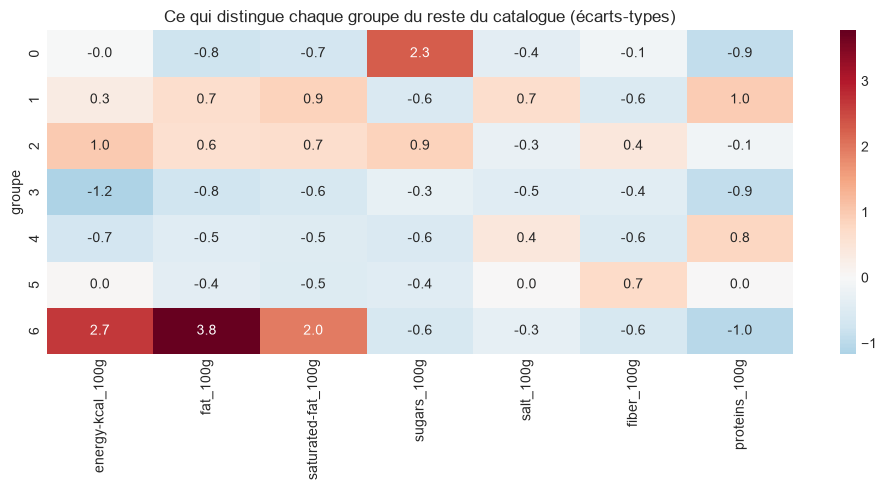

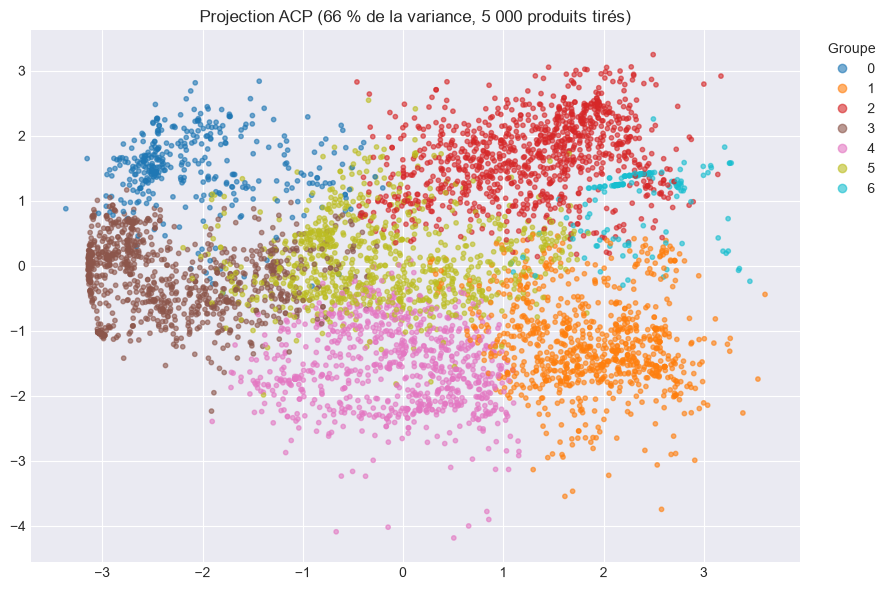

In [59]:
moyennes, ecarts_types = cat[COLS].mean(), cat[COLS].std()
ecarts = ((profil[COLS] - moyennes) / ecarts_types).round(2)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(ecarts, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Ce qui distingue chaque groupe du reste du catalogue (écarts-types)")
plt.tight_layout(); plt.show()

# Projection ACP (échantillon de 5 000 points pour la lisibilité)
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X)
idx = np.random.RandomState(SEED).choice(len(X), 5000, replace=False)
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(coords[idx, 0], coords[idx, 1], c=cat["groupe"].to_numpy()[idx], cmap="tab10", s=10, alpha=0.6)
ax.legend(*sc.legend_elements(), title="Groupe", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title(f"Projection ACP ({pca.explained_variance_ratio_.sum() * 100:.0f} % de la variance, 5 000 produits tirés)")
plt.tight_layout(); plt.show()

> La heatmap compare des moyennes **observées** (fibres non imputées), alors que K-Means a vu les fibres imputées : pour les fibres, l'écart affiché est donc une indication, pas exactement ce qu'a vu le modèle.

🎓 **Lecture de l'ACP.** Les groupes se touchent : c'est normal et c'est cohérent avec la silhouette de ~0,3. Ils forment un continuum découpé en zones, pas des îlots. Si vous aviez vu des îlots nets séparés, il faudrait se méfier (outliers).

In [60]:
LIBELLES = {"energy-kcal_100g": "calories", "fat_100g": "lipides", "saturated-fat_100g": "graisses saturées",
            "sugars_100g": "sucres", "salt_100g": "sel", "fiber_100g": "fibres", "proteins_100g": "protéines"}

def nommer_groupe(ecarts_groupe):
    # Nom provisoire : les deux écarts les plus marqués (riche en / pauvre en)
    top = ecarts_groupe.abs().sort_values(ascending=False).index[:2]
    return " et ".join(("riche en " if ecarts_groupe[c] > 0 else "pauvre en ") + LIBELLES[c] for c in top)

for g in ecarts.index:
    print(f"Groupe {g} ({int(profil.loc[g, 'effectif'])} produits) : {nommer_groupe(ecarts.loc[g])}")

Groupe 0 (2290 produits) : riche en sucres et pauvre en protéines
Groupe 1 (4962 produits) : riche en protéines et riche en graisses saturées
Groupe 2 (6032 produits) : riche en calories et riche en sucres
Groupe 3 (5744 produits) : pauvre en calories et pauvre en protéines
Groupe 4 (4953 produits) : riche en protéines et pauvre en calories
Groupe 5 (5128 produits) : riche en fibres et pauvre en graisses saturées
Groupe 6 (886 produits) : riche en lipides et riche en calories


In [61]:
# Les noms sont attribués d'après le PROFIL, par des règles lisibles, et jamais d'après le numéro :
# ils restent justes si une autre graine ou une autre version de scikit-learn renumérote les groupes.
# Ces règles ont été écrites après lecture des profils ci-dessus, et ne valent que pour k = 7.
p = profil[COLS]
restants = list(p.index)

def prendre(critere):
    # Groupe restant qui maximise le critère ; il est retiré des candidats suivants
    g = critere[restants].idxmax()
    restants.remove(g)
    return g

NOMS_METIER = {}
NOMS_METIER[prendre(p["fat_100g"])] = "Huiles et matières grasses"
NOMS_METIER[prendre(p["sugars_100g"])] = "Confiseries et fruits secs très sucrés"
NOMS_METIER[prendre(p["sugars_100g"])] = "Biscuits et chocolats gras et sucrés"
NOMS_METIER[prendre(p["fiber_100g"])] = "Céréales, pains et plats riches en fibres"
NOMS_METIER[prendre(-p["energy-kcal_100g"])] = "Boissons, fruits, légumes et laitages légers"
NOMS_METIER[prendre(p["fat_100g"])] = "Fromages et charcuteries gras et salés"
NOMS_METIER[prendre(p["proteins_100g"])] = "Viandes, poissons et plats protéinés maigres"

# Contrôle humain : chaque nom face à ses chiffres clés et à son rayon dominant
rayon_dom = cat.groupby("groupe")["pnns_groups_1"].agg(lambda s: f"{s.value_counts().index[0]} ({100 * s.value_counts(normalize=True).iloc[0]:.0f} %)")
display(p.assign(nom=pd.Series(NOMS_METIER), rayon_dominant=rayon_dom)[["nom", "rayon_dominant"] + COLS])

assert set(NOMS_METIER) == set(ecarts.index), "Un nom par groupe est attendu."
assert len(set(NOMS_METIER.values())) == len(NOMS_METIER), "Deux groupes portent le même nom."
cat["segment"] = cat["groupe"].map(NOMS_METIER)
display(cat["segment"].value_counts().to_frame("produits"))

,nom,rayon_dominant,energy-kcal_100g,fat_100g,saturated-fat_100g,sugars_100g,salt_100g,fiber_100g,proteins_100g
groupe,,,,,,,,,
0,Confiseries et fruits secs très sucrés,Sugary snacks (69 %),277.9,0.9,0.3,55.6,0.3,2.1,1.5
1,Fromages et charcuteries gras et salés,Fish Meat Eggs (43 %),338.4,27.9,13.2,1.2,2.1,0.4,17.0
2,Biscuits et chocolats gras et sucrés,Sugary snacks (73 %),469.9,26.9,11.4,29.0,0.5,4.1,7.8
3,"Boissons, fruits, légumes et laitages légers",Beverages (37 %),57.2,1.4,0.6,6.3,0.2,1.0,1.5
4,"Viandes, poissons et plats protéinés maigres",Fish Meat Eggs (66 %),149.6,7.1,2.0,1.3,1.7,0.4,15.7
5,"Céréales, pains et plats riches en fibres",Cereals and potatoes (49 %),284.8,8.4,1.6,4.1,1.0,5.3,9.1
6,Huiles et matières grasses,Fat and sauces (96 %),783.6,86.4,22.3,0.4,0.4,0.1,0.4


,produits
segment,
Biscuits et chocolats gras et sucrés,6032
"Boissons, fruits, légumes et laitages légers",5744
"Céréales, pains et plats riches en fibres",5128
Fromages et charcuteries gras et salés,4962
"Viandes, poissons et plats protéinés maigres",4953
Confiseries et fruits secs très sucrés,2290
Huiles et matières grasses,886


🎓 **Pourquoi des règles plutôt qu'un dictionnaire `{0: "…", 1: "…"}` ?** Les numéros de groupe ne sont pas stables : une autre graine, une autre version de scikit-learn ou un nettoyage légèrement différent les renumérote. C'est arrivé pendant la préparation de ce notebook : en ajustant une règle de nettoyage (quelques dizaines de produits sur 30 000), tous les groupes ont changé de numéro. Un dictionnaire écrit à la main aurait alors donné des noms faux **sans aucune erreur**. Nommer par le profil, c'est appliquer littéralement la consigne du TP. En revanche ces règles ne valent que pour k = 7 : si vous changez k, relisez les profils et réécrivez-les.

### Un groupe n'est pas une famille de substitution (section 4.4 du TP)
Vérifions la raison n°1 sur vos données : combien de sous-catégories chaque groupe contient-il ?

In [62]:
melange = cat.groupby("segment")["pnns_groups_2"].agg(
    sous_categories="nunique",
    principales=lambda s: ", ".join(s.value_counts().index[:4]),
)
display(melange.sort_values("sous_categories", ascending=False))

,sous_categories,principales
segment,,
"Boissons, fruits, légumes et laitages légers",38,"Milk and yogurt, Vegetables, Sweetened beverag..."
"Viandes, poissons et plats protéinés maigres",33,"Meat, Fish and seafood, One-dish meals, Proces..."
Biscuits et chocolats gras et sucrés,32,"Biscuits and cakes, Sweets, Chocolate products..."
Fromages et charcuteries gras et salés,32,"Cheese, Processed meat, Salty and fatty produc..."
"Céréales, pains et plats riches en fibres",31,"Cereals, Bread, One-dish meals, Appetizers"
Confiseries et fruits secs très sucrés,23,"Sweets, Dried fruits, Biscuits and cakes, Fruits"
Huiles et matières grasses,12,"Fats, Dressings and sauces, Cereals, Cheese"


Un même groupe réunit plusieurs sous-catégories : des produits d'**usages différents** mais au profil proche. Personne ne remplace une barre chocolatée par un jus de fruits. La règle de garde de l'après-midi filtre donc **d'abord** sur la sous-catégorie, et ne retient de la matinée que l'idée de **distance entre nutriments normalisés**.

Ce qu'apportent les segments : **expliquer** une suggestion (« vous passez du segment *X* au segment *Y* »), pas la produire.

## 7. Bilan : vos erreurs et leur correction

| # | Votre notebook | Problème | Correction |
|---|---|---|---|
| 1 | Seulement `Beverages` | Hors consigne (le TP segmente le catalogue) ; un rayon homogène amplifie le poids des outliers | Tout le catalogue |
| 2 | Aucun contrôle des valeurs impossibles | Un « cluster salé » qui n'était que 5 erreurs de saisie | Règles de plausibilité comptées, avec tolérance d'arrondi, et ce qu'elles écartent affiché |
| 3 | Médiane du rayon (juste pour les boissons), mais sans fibres | Imputation sans effet sur vos 7 variables ; ne se généralise pas à tout le catalogue | Médiane par `pnns_groups_2`, fibres incluses *(affinement, pas une erreur)* |
| 4 | `StandardScaler` sans `log1p` | **Cause principale** du « 1 bloc + des poches » : les vrais produits extrêmes dictent les groupes | `log1p` si asymétrie > 1, puis `StandardScaler` |
| 5 | Silhouette mesurée sur les données brutes | Valeurs fausses | Mesure sur la matrice normalisée *(déjà corrigé chez vous)* |
| 6 | `KneeLocator` avec un axe x décalé | Coude décalé d'un cran | x = les k réellement testés *(déjà corrigé)* |
| 7 | Choix de k justifié par des scores, mal recopiés | Contredit par le propre tableau | Règle écrite : coude + silhouette + taille minimale + lisibilité |
| 8 | Silhouette de 0,87 vue comme un succès | Signe d'outliers, pas de bonne séparation | ~0,3 sur données propres : attendu pour un continuum |
| 9 | Noms basés sur 5 exemples | Non vérifiés | Profils, écarts, croisement rayon / Nutri-Score |
| 10 | `df.iloc[group.index]` ; `bal["inertie"].iloc[optimal_k]` ; `legend()` vide | Fonctionne ici par chance (index `RangeIndex`) ; position confondue avec une valeur de k | `.loc` ; indexer par la valeur de k ; pas de légende sans label |
| 11 | Deux groupes nommés « Cluster 3 » ; k de 2 à 12 au lieu de 2 à 10 | Détails de relecture ; écart à la consigne | Relire la liste ; `range(2, 11)` |
| 12 | `kneed` utilisé mais absent de l'environnement du projet | Notebook non ré-exécutable tel quel | L'ajouter à `requirements.txt`, ou une fonction du coude maison comme ici |

### À retenir
- **Un bon score n'est pas un bon clustering.** Avant de nommer un groupe, regardez qui est dedans.
- Nettoyer, imputer, transformer, normaliser : **dans cet ordre, et chaque choix se chiffre.**
- Les noms viennent de votre interprétation, pas du modèle.

### Suite du TP (l'après-midi)
`src/substitution.py` avec ses tests, les règles de garde, puis la validation à la main sur 20 produits. Pour cela, deux points à régler dès maintenant : le parquet n'a **ni `bio`, ni `labels_tags`** (décidez comment traiter la règle bio), et `pnns_groups_1` / `pnns_groups_2` servent de rayon / sous-catégorie.

*Données : Open Food Facts (ODbL).*